# 07 · Default model, ten tuned families

Same target and validation as before: log10(views), 5 folds grouped by brand. New here: a named default model against the baselines, Brand24's rule on X laid out, and a real hyperparameter search (nested, so tuning never sees the fold that is scored).

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, extra_models as em, extra_features as ef, modeling as mo, new_ideas as ni, tuning as tn, guide_figures as gf
from validation import mae_ci

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 80)

In [2]:
f, meta = em.load(ROOT); raw = eu.load(ROOT).astype({'mention_id': str})
f[em.ENG].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_followers,6613.0,3.51,1.41,0.0,2.55,3.53,4.48,8.05
log_likes,6629.0,2.47,2.39,0.0,0.00,1.95,4.01,13.53
log_comments,5421.0,1.23,1.52,0.0,0.00,0.69,1.95,9.07
log_shares,5745.0,0.64,1.40,0.0,0.00,0.00,0.69,13.24
na_likes,6735.0,0.02,0.12,0.0,0.00,0.00,0.00,1.00
na_comments,6735.0,0.20,0.40,0.0,0.00,0.00,0.00,1.00
na_shares,6735.0,0.15,0.35,0.0,0.00,0.00,0.00,1.00
na_followers,6735.0,0.00,0.04,0.0,0.00,0.00,0.00,1.00


## 1 · One default model against the baselines
`HistGradientBoostingRegressor()` with scikit-learn's defaults, nothing chosen by us.

platform,TikTok,X (Twitter),YouTube
model,,,
constant x followers,0.919,0.879,0.855
default model: followers,0.607,0.598,0.787
default model: followers + reactions,0.292,0.492,0.526
median views,0.663,0.667,0.944


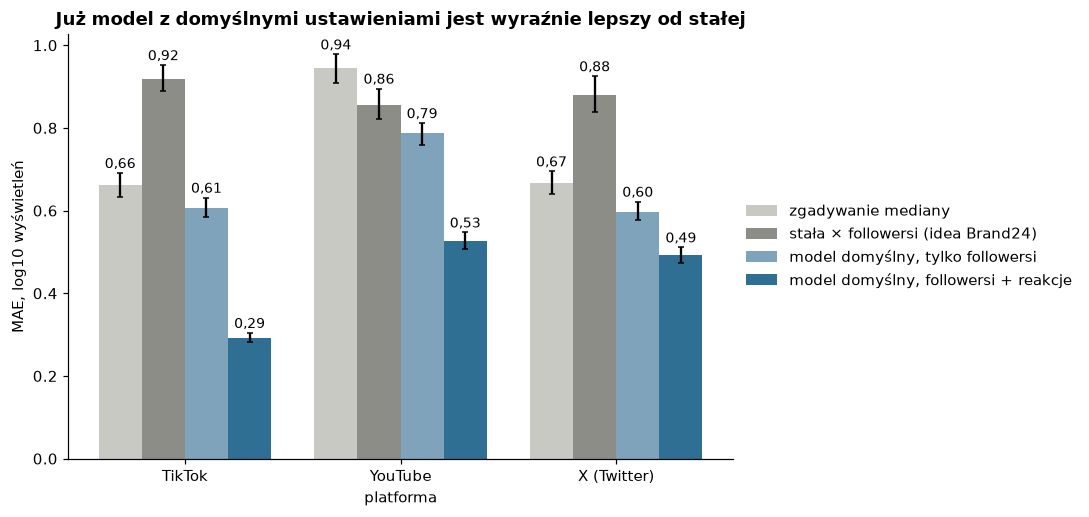

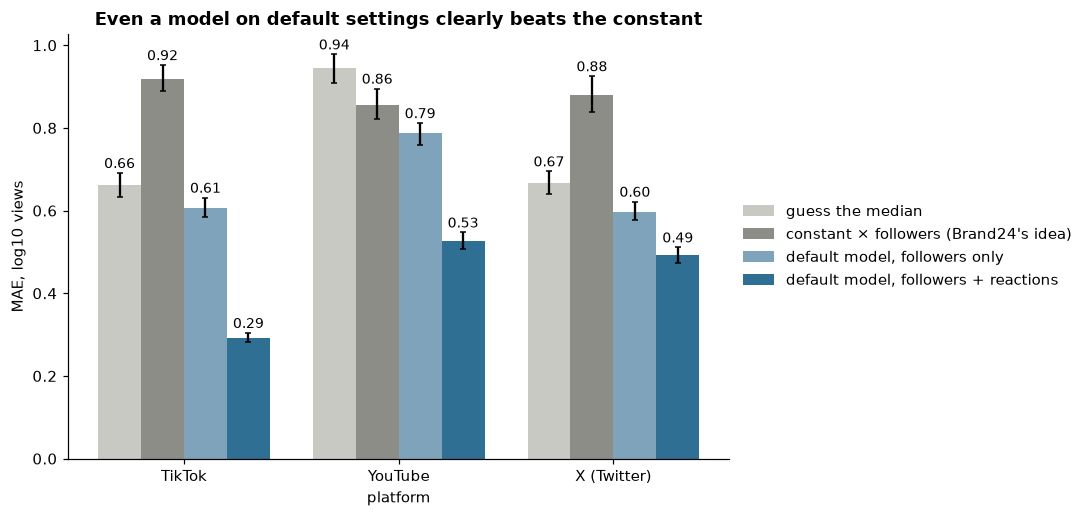

In [3]:
base = gf.baseline_table(f, meta); display(base.pivot(index='model', columns='platform', values='MAE').round(3))
for l in ('pl', 'en'): gf.plot_baseline(base, FIG / f'baseline_{l}.png', l)

## 2 · Brand24's rule on X
Only on rows where both reach and views exist.

{
 "rows": 1639,
 "zero reach share": 0.09095951192457016,
 "share exactly 0.1 x followers": 0.2129783693843594,
 "Brand24 MAE": 1.0828435556783087,
 "Brand24 low": 1.0430724028993825,
 "Brand24 high": 1.118520464669312,
 "model MAE": 0.4738426865591159,
 "model low": 0.4532876361907046,
 "model high": 0.4962075695121333,
 "gain": 0.6090008691191928,
 "gain low": 0.5653407919726924,
 "gain high": 0.6522123076472975,
 "Brand24 bias": -0.8415152015262158,
 "model bias": 0.00039570913308897046
}


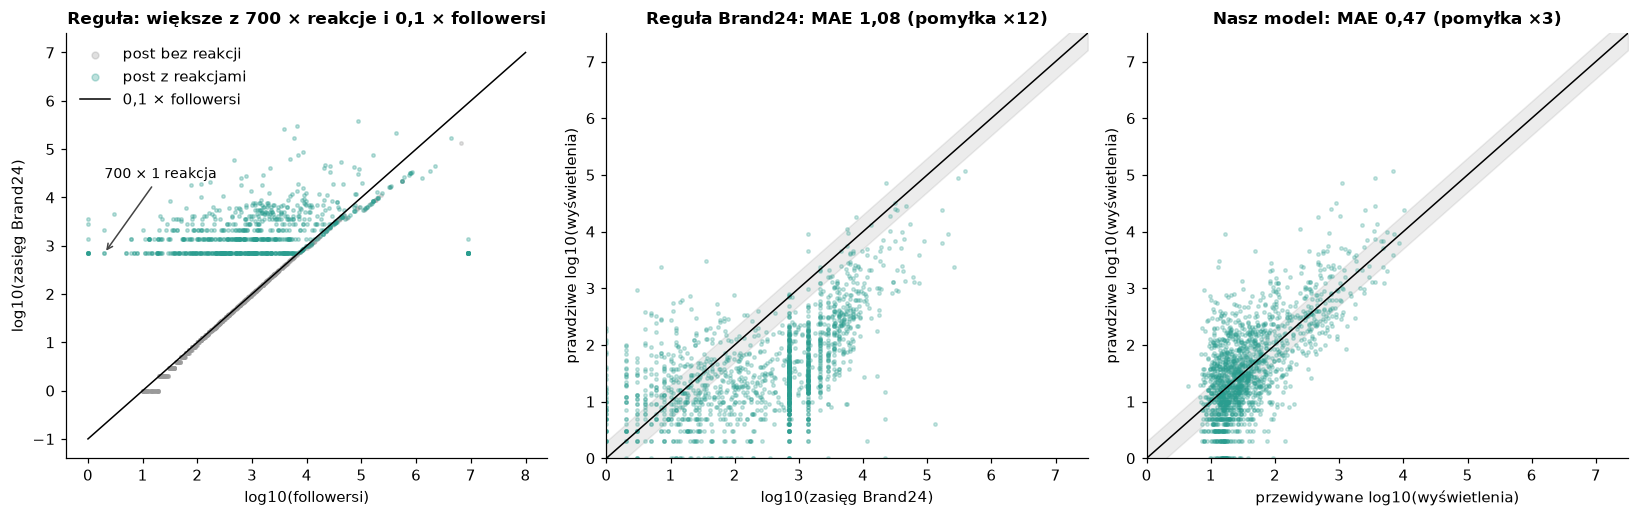

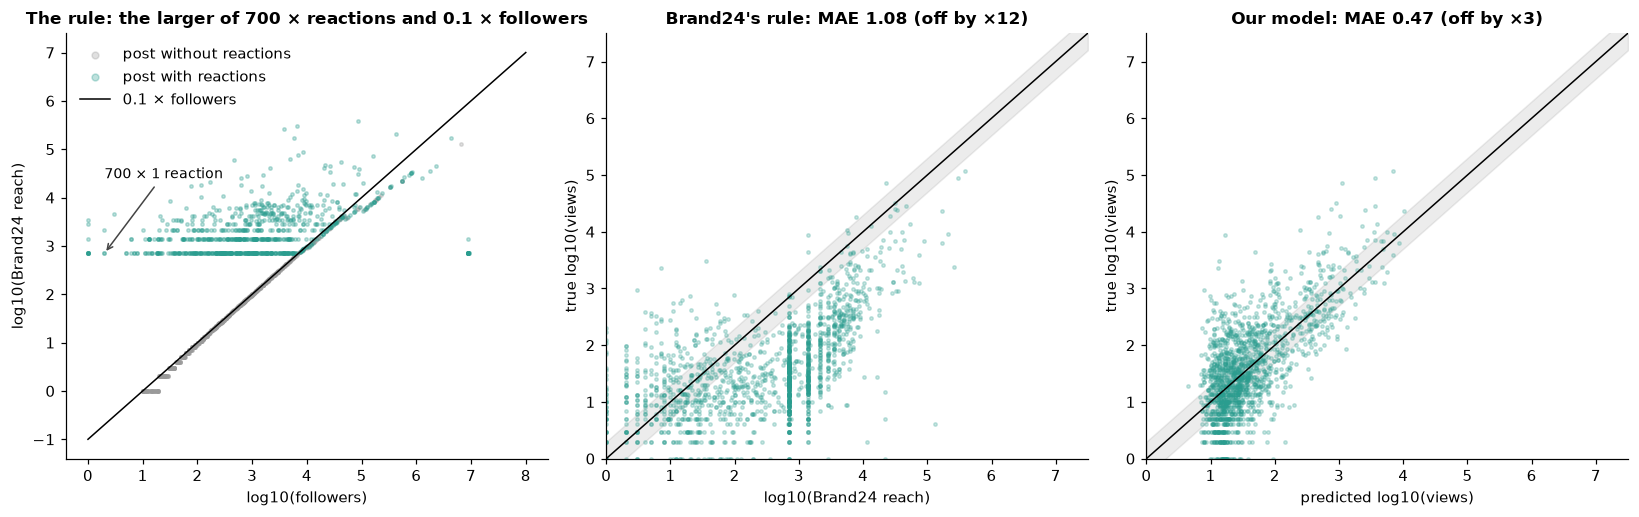

In [4]:
xs, xM, xr, xp = gf.x_rule(f, meta, raw); print(json.dumps(xs, indent=1))
for l in ('pl', 'en'): gf.plot_x_rule(xs, xM, xr, xp, FIG / f'x_rule_{l}.png', l)

## 3 · Search
Random search, 40 settings per family per outer fold, inner 3-fold brand-grouped CV, objective MAE.

In [5]:
runs = {p: tn.nested(f, meta, p) for p in mo.PLATS}
tab = pd.concat([runs[p][0] for p in mo.PLATS], ignore_index=True)
tab.drop(columns='picks').round(3)

TikTok ridge 0.278 -> 0.277


TikTok kNN 0.304 -> 0.283


TikTok SVR (RBF) 0.275 -> 0.271


TikTok MLP 0.276 -> 0.276


TikTok random forest 0.3 -> 0.275


TikTok extra trees 0.317 -> 0.275


... (21 outputs left out)

X (Twitter) LightGBM 0.495 -> 0.475


X (Twitter) XGBoost 0.536 -> 0.467


X (Twitter) CatBoost 0.488 -> 0.47


,platform,model,default MAE,default low,default high,tuned MAE,tuned low,tuned high,gain,gain low,gain high,inner MAE
0,TikTok,ridge,0.278,0.268,0.288,0.277,0.267,0.287,0.001,0.000,0.003,0.278
1,TikTok,kNN,0.304,0.293,0.316,0.283,0.273,0.295,0.021,0.014,0.026,0.288
2,TikTok,SVR (RBF),0.275,0.264,0.286,0.271,0.261,0.282,0.003,0.001,0.006,0.273
3,TikTok,MLP,0.276,0.265,0.284,0.276,0.265,0.286,-0.000,-0.003,0.002,0.277
4,TikTok,random forest,0.300,0.290,0.312,0.275,0.266,0.286,0.025,0.020,0.030,0.278
5,TikTok,extra trees,0.317,0.306,0.329,0.275,0.264,0.285,0.042,0.035,0.050,0.278
6,TikTok,boosting (sklearn),0.292,0.282,0.304,0.276,0.267,0.287,0.017,0.012,0.022,0.278
7,TikTok,LightGBM,0.294,0.283,0.305,0.275,0.266,0.287,0.018,0.014,0.023,0.279
8,TikTok,XGBoost,0.317,0.307,0.330,0.273,0.262,0.283,0.044,0.037,0.051,0.275
9,TikTok,CatBoost,0.285,0.275,0.297,0.272,0.261,0.283,0.013,0.009,0.017,0.273


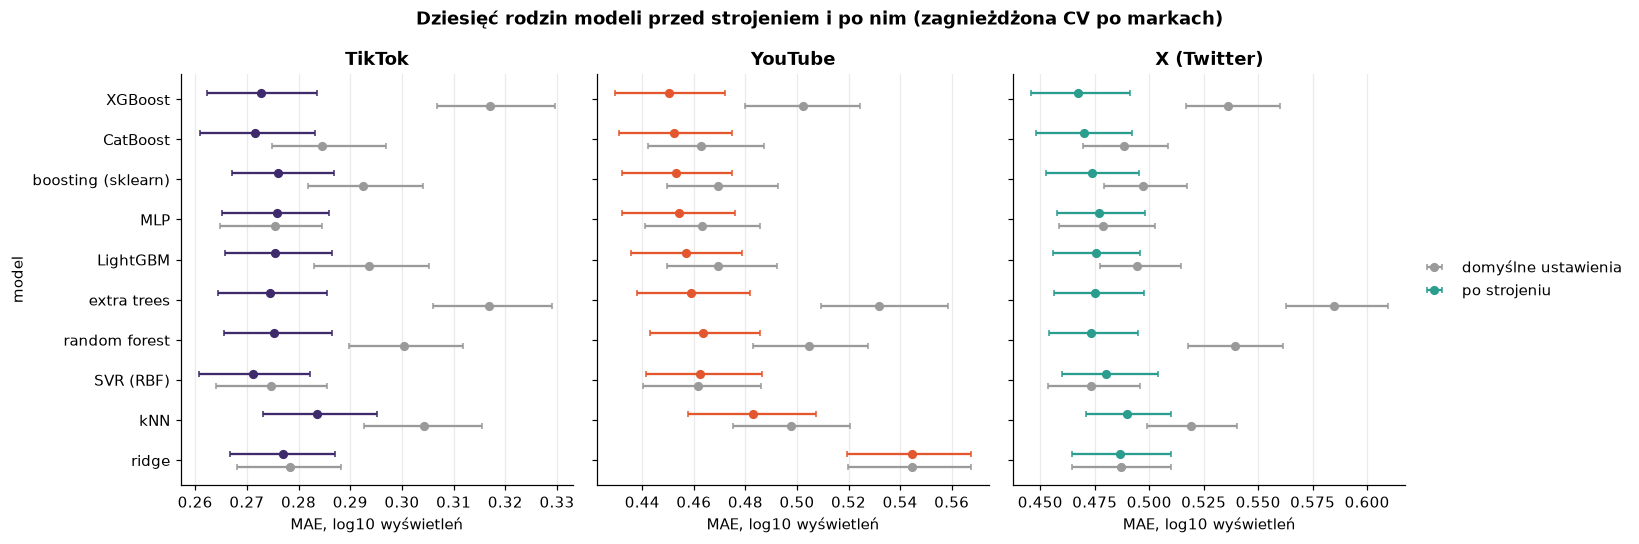

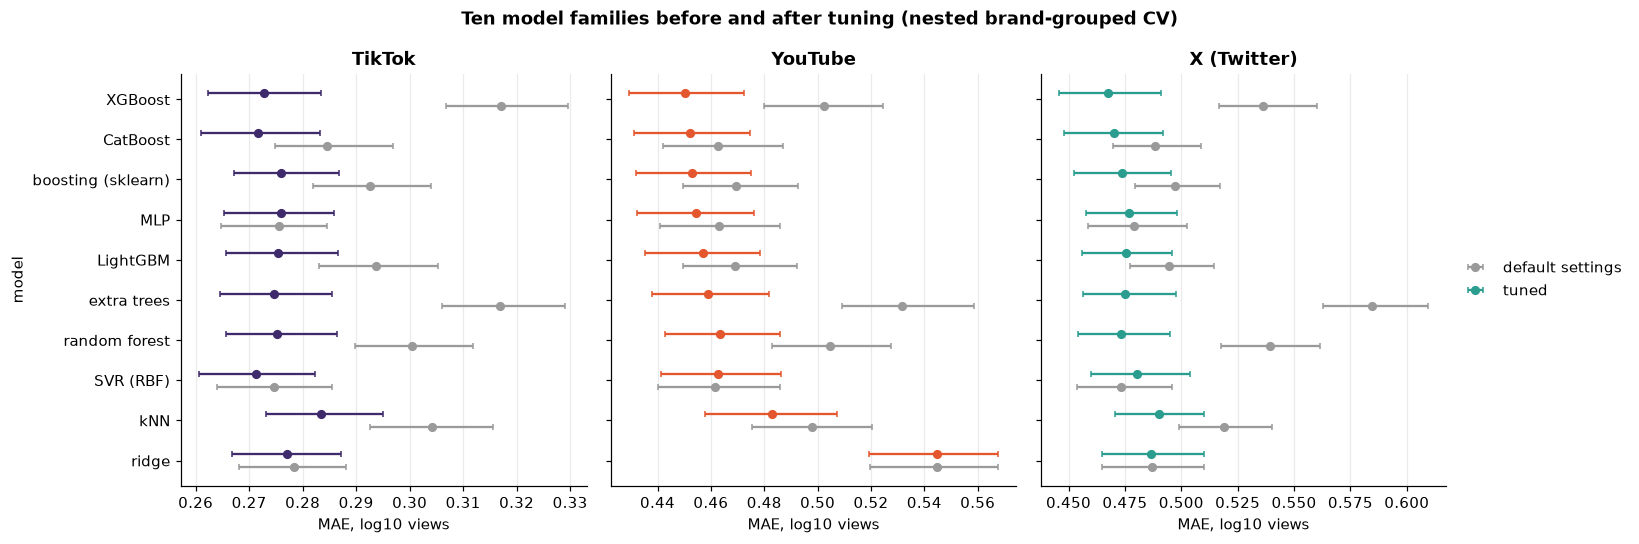

In [6]:
for l in ('pl', 'en'): tn.plot_families(tab, FIG / f'families_{l}.png', l)

## 4 · Does tuning matter, and does anything beat the simplest model?
Paired on the same folds, brand-cluster bootstrap.

In [7]:
rows = []
for p in mo.PLATS:
    t, bl, o = runs[p]; best = t.loc[t["inner MAE"].idxmin(), "model"]; y, g = o["y"], o["brand"]; ridge = o["pred"]["ridge"]; d = ni.paired_diff(y, ridge, o["pred"][best], g)
    bp = np.mean([o["pred"][k] for k in bl["members"]], axis=0); db = ni.paired_diff(y, ridge, bp, g)
    rows.append({"platform": eu.NAMES[p], "picked by inner CV": best, "MAE": np.abs(y - o["pred"][best]).mean(), "ridge MAE": np.abs(y - ridge).mean(), "gain over ridge": d[0], "low": d[1], "high": d[2], "blend of top 3": bl["MAE"], "blend gain over ridge": db[0], "blend low": db[1], "blend high": db[2], "blend members": ", ".join(bl["members"])})
versus = pd.DataFrame(rows); versus.round(3)

,platform,picked by inner CV,MAE,ridge MAE,gain over ridge,low,high,blend of top 3,blend gain over ridge,blend low,blend high,blend members
0,TikTok,SVR (RBF),0.271,0.277,0.006,0.003,0.008,0.270,0.007,0.004,0.010,"SVR (RBF), CatBoost, XGBoost"
1,YouTube,CatBoost,0.452,0.545,0.092,0.077,0.108,0.446,0.098,0.083,0.114,"CatBoost, XGBoost, MLP"
2,X (Twitter),CatBoost,0.470,0.487,0.017,0.009,0.025,0.469,0.018,0.010,0.027,"CatBoost, XGBoost, boosting (sklearn)"


## 5 · Are the picked settings stable across folds?
For the family the inner CV prefers on each platform.

In [8]:
for p in mo.PLATS:
    t = runs[p][0]; best = t.loc[t["inner MAE"].idxmin()]; print(eu.NAMES[p], best.model); display(pd.DataFrame(best.picks).round(3))

TikTok SVR (RBF)


,C,epsilon,gamma
0,31.429,0.116,0.004
1,2.092,0.071,0.031
2,31.429,0.116,0.004
3,9.718,0.166,0.036
4,31.429,0.116,0.004


YouTube CatBoost


,depth,iterations,l2_leaf_reg,learning_rate,loss_function
0,5,444,0.527,0.080,MAE
1,4,406,4.844,0.046,MAE
2,5,444,0.527,0.080,MAE
3,3,459,7.432,0.042,MAE
4,8,445,0.116,0.014,RMSE


X (Twitter) CatBoost


,depth,iterations,l2_leaf_reg,learning_rate,loss_function
0,3,459,7.432,0.042,MAE
1,5,332,0.569,0.018,RMSE
2,2,286,3.236,0.055,MAE
3,3,269,10.042,0.086,MAE
4,2,147,0.829,0.097,RMSE


## 6 · Tuned models with text columns
Does a tuned booster find more in text statistics and TF-IDF topics than the fixed extra trees did?

In [9]:
G = ef.build(ROOT, f, meta); ex = pd.concat([G["text stats"], G["TF-IDF SVD (30)"]], axis=1); rows = []
for p in mo.PLATS:
    t2, _, o2 = tn.nested(f, meta, p, names=["CatBoost", "LightGBM"], extra=ex); o1 = runs[p][2]
    for m_ in ["CatBoost", "LightGBM"]:
        d = ni.paired_diff(o1["y"], o1["pred"][m_], o2["pred"][m_], o1["brand"]); rows.append({"platform": eu.NAMES[p], "model": m_, "no text": np.abs(o1["y"] - o1["pred"][m_]).mean(), "with text": np.abs(o1["y"] - o2["pred"][m_]).mean(), "gain": d[0], "low": d[1], "high": d[2]})
text_gain = pd.DataFrame(rows); text_gain.round(3)

TikTok LightGBM 0.286 -> 0.274


TikTok CatBoost 0.283 -> 0.273


YouTube LightGBM 0.455 -> 0.447


YouTube CatBoost 0.454 -> 0.444


X (Twitter) LightGBM 0.47 -> 0.462


X (Twitter) CatBoost 0.467 -> 0.464


,platform,model,no text,with text,gain,low,high
0,TikTok,CatBoost,0.272,0.273,-0.002,-0.005,0.001
1,TikTok,LightGBM,0.275,0.274,0.001,-0.001,0.004
2,YouTube,CatBoost,0.452,0.444,0.008,-0.002,0.018
3,YouTube,LightGBM,0.457,0.447,0.009,0.000,0.019
4,X (Twitter),CatBoost,0.470,0.464,0.006,-0.003,0.014
5,X (Twitter),LightGBM,0.475,0.462,0.013,0.003,0.023


## 7 · Predicted vs true with the model the inner CV prefers

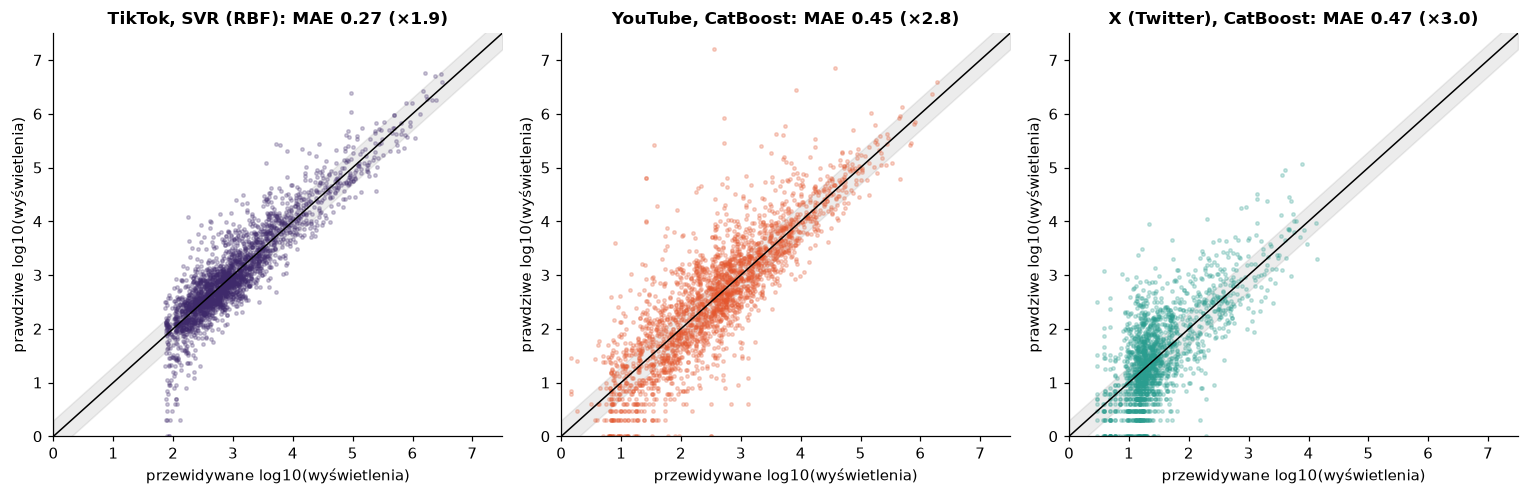

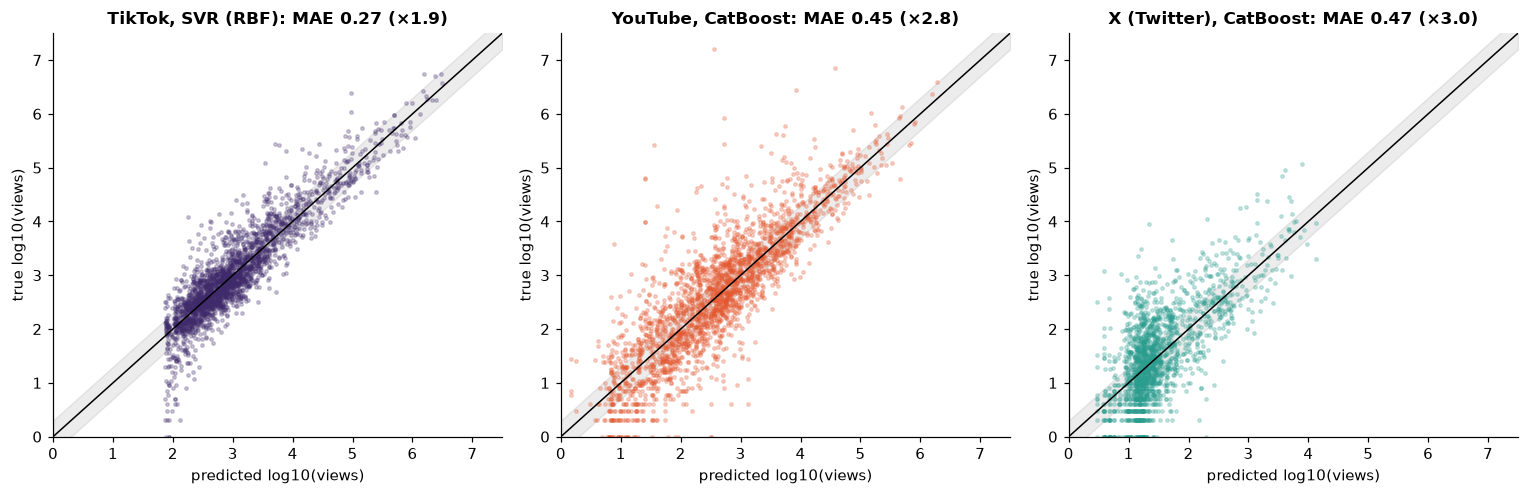

In [10]:
def scatter(lang):
    pl = lang == "pl"; fig, ax = plt.subplots(1, 3, figsize=(14, 4.6)); lim = [0, 7.5]
    for a, p in zip(ax, mo.PLATS):
        t, _, o = runs[p]; b = t.loc[t["inner MAE"].idxmin(), "model"]; pr = o["pred"][b]; e = np.abs(o["y"] - pr).mean(); a.plot(lim, lim, color="black", lw=1); a.fill_between(lim, [l - .3 for l in lim], [l + .3 for l in lim], color="grey", alpha=.15); a.scatter(pr, o["y"], s=5, alpha=.25, color=eu.PCOL[p]); a.set_xlim(lim); a.set_ylim(lim)
        a.set_title(f"{eu.NAMES[p]}, {b}: MAE {e:.2f} (×{10 ** e:.1f})", fontweight="bold", fontsize=11); a.set_xlabel("przewidywane log10(wyświetlenia)" if pl else "predicted log10(views)"); a.set_ylabel("prawdziwe log10(wyświetlenia)" if pl else "true log10(views)")
    plt.tight_layout(); fig.savefig(FIG / f"inplatform_{lang}.png", dpi=170, bbox_inches="tight"); plt.show()
for l in ("pl", "en"): scatter(l)

## Takeaways
- **A default model already beats the constant:** scikit-learn's defaults with followers + reactions give 0.29 / 0.53 / 0.49 against 0.92 / 0.86 / 0.88 for constant × followers.
- **Tuning matters for models that overfit by default** (extra trees on X 0.585 to 0.475, XGBoost 0.536 to 0.467), much less for ridge, MLP and SVR.
- **After tuning the families converge:** TikTok 0.27-0.28, YouTube 0.45-0.48 (ridge 0.545 is the exception), X 0.47-0.49. Earlier we called the families equal; that holds for trees and boosters, not for a linear model on YouTube.
- **Best against ridge:** +0.006 TikTok, +0.092 YouTube, +0.017 X, all with CI above zero. Real, but small next to the 0.1-0.3 that reactions bring over followers alone.
- **Tuned boosters with text:** at most +0.013, and only LightGBM on X has a CI clearly above zero. Tuning does not unlock text.
- The family reported per platform is chosen by inner CV only, not on the test folds.

In [11]:
json.dump({"baseline": base.to_dict("records"), "x_rule": xs, "families": tab.to_dict("records"), "blend": [runs[p][1] for p in mo.PLATS], "versus": versus.to_dict("records"), "text_gain": text_gain.to_dict("records")}, open(ROOT / "data" / "processed" / "tuning_numbers.json", "w"), indent=1, default=float)